# Capítulo 3 · Qué permite afirmar un modelo causal SCM

Una agencia debe decidir si continúa un programa de capacitación. Quienes participaron ganan más que quienes no, pero ¿esa diferencia se debe al programa o a quiénes decidieron inscribirse?

**La pregunta de hoy:** ¿qué podemos afirmar con datos y qué solo podemos afirmar con supuestos?

**En esta sesión vamos a:**

1. Construir un modelo causal estructural (SCM) e intervenirlo.
2. Calcular el contrafactual de una persona concreta.
3. Comparar dos mundos que producen la misma tabla pero tienen efectos distintos.
4. Contrastar una implicación del grafo con los datos.
5. Repetir el cálculo con DoWhy, declarando el grafo.

> *Nota:* todos los datos de esta sesión son simulados, en unidades normalizadas. Eso es lo que nos permite comparar cada estimación con la respuesta verdadera.

# Parte I · Un mundo donde conocemos la verdad

## La decisión

La agencia quiere saber si el programa sirve. Pero esa frase esconde dos preguntas distintas:

- **A:** ¿cuánto ganan, en promedio, quienes participaron?
- **B:** ¿cuánto cambiaría el ingreso si *obligáramos* a participar a toda la población?

La primera se responde mirando la tabla. La segunda es la que decide si el programa continúa.

**Para discutir:** ¿dan lo mismo?

## El grafo

Llamemos *D* a la **participación** (1 = participó, 0 = no participó), *Y* al **ingreso** y *U* a la **motivación**, que no se observa.

- D → Y · el programa afecta el ingreso
- U → D · los más motivados se inscriben más
- U → Y · los más motivados ganan más

**Antes de ejecutar:** hay dos caminos entre D e Y. ¿Cuál es el efecto del programa y cuál nos engaña?

In [16]:
import numpy as np
import pandas as pd
from lib.data_io import load_scenario
from lib.identification import ols_ate

## Construir el SCM

$M = \langle E, V, F, P(e) \rangle$, donde conocemos todo, a diferencia de la realidad:

| Pieza | En este mundo |
|---|---|
| Exógenas $E$ | motivación $U$, ruidos $\varepsilon_D$, $\varepsilon_Y$ |
| Endógenas $V$ | participación $D$, ingreso $Y$ |
| Ecuaciones $F$ | $D = \mathbb{1}[U + \varepsilon_D > 0.3]$ ; $Y = 0.4D + 0.9U + \varepsilon_Y$ |
| $P(E)$ | $U, \varepsilon_D \sim N(0,1)$ ;  $\varepsilon_Y \sim N(0, 0.5^2)$ |

Efecto verdadero: **0.4**. Las exógenas quedan guardadas, porque más adelante seguiremos a una persona concreta.

**Antes de ejecutar:** ¿la diferencia de medias saldrá mayor, menor o igual a 0.4?

In [17]:
# Parámetros del SCM
EFECTO = 0.4    # efecto causal verdadero de D sobre Y
BETA_U = 0.9    # efecto de la motivación sobre Y
UMBRAL = 0.3    # umbral de participación

rng = np.random.default_rng(7)
n = 50_000

# Exógenas: lo que el modelo no explica
U = rng.normal(size=n)                      # motivación
ruido_D = rng.normal(size=n)
ruido_Y = rng.normal(scale=0.5, size=n)

# Endógenas: una ecuación por variable
D = (U + ruido_D > UMBRAL).astype(int)      # participación
Y = EFECTO * D + BETA_U * U + ruido_Y       # ingreso

muestra = pd.DataFrame({"motivación (U)": U.round(3),
                        "participó (D)": D,
                        "ingreso (Y)": Y.round(3)})

print("Cinco personas de las", f"{n:,}".replace(",", " "), "que genera el SCM:\n")
print(muestra.head().to_string(index=False))
print("\n(U no se observa en la realidad: aquí la vemos porque simulamos el mundo.)")

diferencia = Y[D == 1].mean() - Y[D == 0].mean()
print(f"\nDiferencia de ingreso entre participantes y no participantes: {diferencia:.3f}")
print(f"Efecto verdadero del programa: {EFECTO}")

Cinco personas de las 50 000 que genera el SCM:

 motivación (U)  participó (D)  ingreso (Y)
          0.001              0       -0.053
          0.299              1        0.677
         -0.274              0       -0.257
         -0.891              0       -0.660
         -0.455              1       -0.111

(U no se observa en la realidad: aquí la vemos porque simulamos el mundo.)

Diferencia de ingreso entre participantes y no participantes: 1.426
Efecto verdadero del programa: 0.4


In [18]:
# Primero: ¿en qué se diferencian los grupos antes del programa?
promedios = pd.DataFrame({"U": U, "D": D, "Y": Y}).groupby("D")[["U", "Y"]].mean().round(3)
promedios.index = ["no participantes (D=0)", "participantes (D=1)"]
promedios.columns = ["motivación media (U)", "ingreso medio (Y)"]
print(promedios.to_string())

# Ahora separamos la diferencia de 1.426 en sus partes
# Selección: lo que los participantes ganarían de más solo por ser más motivados
seleccion = BETA_U * (U[D == 1].mean() - U[D == 0].mean())
# Azar: diferencia fortuita en el ruido del ingreso entre los grupos
azar = ruido_Y[D == 1].mean() - ruido_Y[D == 0].mean()

descomposicion = pd.Series({"efecto real del programa": EFECTO,
                            "ventaja previa por motivación": seleccion,
                            "azar": azar})
print(f"\n¿De qué está hecha la diferencia de {diferencia:.3f}?\n")
print(descomposicion.round(3).to_string())
print("\nSuma:", round(descomposicion.sum(), 3), "= la diferencia observada")

                        motivación media (U)  ingreso medio (Y)
no participantes (D=0)                -0.477             -0.430
participantes (D=1)                    0.656              0.995

¿De qué está hecha la diferencia de 1.426?

efecto real del programa         0.400
ventaja previa por motivación    1.020
azar                             0.006

Suma: 1.426 = la diferencia observada


**Para discutir:**

1. Si la participación se sorteara, ¿cuál de los tres sumandos desaparecería? ¿Por qué?
2. Si subimos el `UMBRAL`, entra menos gente al programa. ¿Cambia el efecto del programa o cambia quién entra a cada grupo?

## Intervenir: el efecto medio del programa

Con $do(D=d)$ **borramos** la ecuación de participación y fijamos $D=d$ para todos. El resto del SCM sigue igual.

Cada persona conserva su motivación y su ruido, así que la comparamos consigo misma: con programa y sin programa.

**Antes de ejecutar:** ¿qué valor esperas para el efecto de la intervención?

In [28]:
# do(D=1) y do(D=0): fijamos el tratamiento y conservamos las exógenas de cada persona
Y_do1 = EFECTO * 1 + BETA_U * U + ruido_Y
Y_do0 = EFECTO * 0 + BETA_U * U + ruido_Y

print(f"Asociación   (participaron vs. no participaron): {diferencia:>6.3f}")
print(f"Intervención (todos vs. nadie participa):        {(Y_do1 - Y_do0).mean():>6.3f}")
print(f"\nEfecto verdadero del programa: {EFECTO}")

Asociación   (participaron vs. no participaron):  1.426
Intervención (todos vs. nadie participa):         0.400

Efecto verdadero del programa: 0.4


## Contrafactual de una persona: abducción, acción y predicción

Antes preguntamos qué pasaría si interviniéramos a *toda la población*. Ahora preguntamos por *una persona concreta* que participó: ¿cuánto habría ganado si **no** hubiera participado?

Tres pasos, siguiendo a Pearl:

1. **Abducción:** con lo observado ($D$, $Y$) y el valor de $U$ que los genero, que solo conocemos porque es una simulación, recuperamos su ruido $\varepsilon_Y$.
2. **Acción:** fijamos $D = 0$.
3. **Predicción:** recalculamos $Y$ con *su* $U$ y *su* $\varepsilon_Y$.

Si generáramos ruido nuevo, obtendríamos a otra persona, no el contrafactual de esta.

**Antes de ejecutar:** ¿qué efecto individual esperas para esta persona?

In [37]:
i = np.flatnonzero(D == 1)[0]        # la primera persona que participó

epsilon_i = Y[i] - EFECTO - BETA_U * U[i]   # 1. Abducción: su ruido
y_sin = BETA_U * U[i] + epsilon_i           # 2 y 3. Acción D=0 y predicción

print(f"Participó, y ganó:        {Y[i]:.3f}")
print(f"Si no hubiera participado: {y_sin:.3f}")
print(f"Efecto en esta persona:    {Y[i] - y_sin:.3f}")

Participó, y ganó:        0.677
Si no hubiera participado: 0.277
Efecto en esta persona:    0.400


**Para discutir:**

1. ¿Qué paso del cálculo se vuelve imposible si no conocemos $U$? (Pista: sin $U$ no hay abducción.)
2. Esta persona tiene un efecto de 0.4, porque así construimos el SCM. ¿Significa eso que ya sabemos estimar efectos individuales con datos reales?

## Dos mundos, una misma tabla

Llegamos a 0.4 porque conocíamos el SCM. ¿Y si solo tenemos la tabla?

Dos mundos que comparten las dos primeras ecuaciones y difieren en la tercera:

| | Mundo A | Mundo B |
|:--|:--|:--|
| motivación | $U \sim N(0,1)$ | $U \sim N(0,1)$ |
| participación | $D = U + \varepsilon_D$ | $D = U + \varepsilon_D$ |
| ingreso | $Y = D + \varepsilon_Y$, con $\varepsilon_Y \sim N(0,3)$ | $Y = 2U + \varepsilon_Y$, con $\varepsilon_Y \sim N(0,1)$ |
| grafo | $U \to D \to Y$ | $D \leftarrow U \to Y$ |
| distribución de $(D, Y)$ | medias $0$ ; varianzas $2$ y $5$ ; covarianza $2$ | medias $0$ ; varianzas $2$ y $5$ ; covarianza $2$ |

En A el programa causa el ingreso. En B el programa no hace nada: la motivación causa las dos cosas.

Recuerda que $U$ no se observa. Lo único que ve el analista es la tabla de $D$ e $Y$.

**Antes de ejecutar:** ¿podrá esa tabla distinguir los dos mundos?

In [6]:
g = np.random.default_rng(3)
n = 200_000

# Mundo A: el programa causa el ingreso.      U → D → Y
U_a = g.normal(size=n)
D_a = U_a + g.normal(size=n)
Y_a = 1.0 * D_a + g.normal(scale=np.sqrt(3), size=n)

# Mundo B: la motivación causa ambos.        D ← U → Y
U_b = g.normal(size=n)
D_b = U_b + g.normal(size=n)
Y_b = 2.0 * U_b + g.normal(size=n)

print("Lo que se observa de (D, Y):\n")
print(pd.DataFrame({
    "media D":  [D_a.mean(), D_b.mean()],
    "media Y":  [Y_a.mean(), Y_b.mean()],
    "var D":    [D_a.var(), D_b.var()],
    "var Y":    [Y_a.var(), Y_b.var()],
    "cov(D,Y)": [np.cov(D_a, Y_a)[0, 1], np.cov(D_b, Y_b)[0, 1]],
}, index=["Mundo A", "Mundo B"]).round(2).to_string())

print("\nRegresión de Y sobre D:")
print(f"  Mundo A: {np.cov(D_a, Y_a)[0, 1] / D_a.var():.2f}")
print(f"  Mundo B: {np.cov(D_b, Y_b)[0, 1] / D_b.var():.2f}")

print("\nEfecto real del programa, do(D=1) − do(D=0):")
print("  Mundo A (Y = 1.0·D + ruido): 1.0")
print("  Mundo B (Y = 2.0·U + ruido): 0.0")

Lo que se observa de (D, Y):

         media D  media Y  var D  var Y  cov(D,Y)
Mundo A      0.0      0.0   2.01   5.00       2.0
Mundo B      0.0     -0.0   2.00   4.99       2.0

Regresión de Y sobre D:
  Mundo A: 1.00
  Mundo B: 1.00

Efecto real del programa, do(D=1) − do(D=0):
  Mundo A (Y = 1.0·D + ruido): 1.0
  Mundo B (Y = 2.0·U + ruido): 0.0


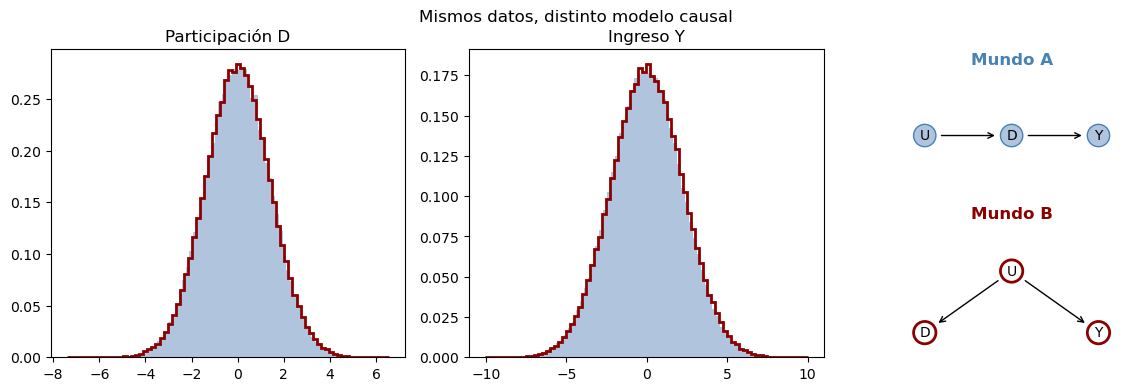

In [38]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1, 0.7]})

ejes[0].hist(D_a, bins=80, density=True, color="lightsteelblue")
ejes[0].hist(D_b, bins=80, density=True, histtype="step", color="darkred", linewidth=2)
ejes[0].set_title("Participación D")

ejes[1].hist(Y_a, bins=80, density=True, color="lightsteelblue")
ejes[1].hist(Y_b, bins=80, density=True, histtype="step", color="darkred", linewidth=2)
ejes[1].set_title("Ingreso Y")

g = ejes[2]
g.axis("off")
g.set_xlim(0, 1)
g.set_ylim(0, 1)
flecha = dict(arrowstyle="->", shrinkA=12, shrinkB=12)

# Mundo A: U → D → Y
nodo_a = dict(boxstyle="circle", facecolor="lightsteelblue", edgecolor="steelblue")
g.text(0.5, 0.95, "Mundo A", color="steelblue", ha="center", fontsize=12, weight="bold")
g.text(0.15, 0.72, "U", ha="center", va="center", bbox=nodo_a)
g.text(0.50, 0.72, "D", ha="center", va="center", bbox=nodo_a)
g.text(0.85, 0.72, "Y", ha="center", va="center", bbox=nodo_a)
g.annotate("", xy=(0.50, 0.72), xytext=(0.15, 0.72), arrowprops=flecha)
g.annotate("", xy=(0.85, 0.72), xytext=(0.50, 0.72), arrowprops=flecha)

# Mundo B: D ← U → Y
nodo_b = dict(boxstyle="circle", facecolor="white", edgecolor="darkred", linewidth=2)
g.text(0.5, 0.45, "Mundo B", color="darkred", ha="center", fontsize=12, weight="bold")
g.text(0.50, 0.28, "U", ha="center", va="center", bbox=nodo_b)
g.text(0.15, 0.08, "D", ha="center", va="center", bbox=nodo_b)
g.text(0.85, 0.08, "Y", ha="center", va="center", bbox=nodo_b)
g.annotate("", xy=(0.15, 0.08), xytext=(0.50, 0.28), arrowprops=flecha)
g.annotate("", xy=(0.85, 0.08), xytext=(0.50, 0.28), arrowprops=flecha)

fig.suptitle("Mismos datos, distinto modelo causal")
plt.show()

**Para discutir:**

1. Con más datos o un modelo más potente, ¿podrías distinguir A de B con esta tabla?
2. ¿Qué información te permitiría elegir entre ambos mundos?

*Conclusión:* la tabla no contiene la respuesta, así que ningún modelo la encontrará. Hace falta un experimento o un supuesto. Esto es el Teorema de la Jerarquía Causal: la asociación no determina la intervención.

# Parte II · Contrastar el grafo con los datos

Sea $Z$ la distancia al centro de capacitación, que influye en la participación.

Un grafo hace promesas que los datos pueden desmentir. Esta: si la única conexión entre $Z$ e $Y$ pasa por $D$, entonces al descontar $D$ no debería quedar relación entre $Z$ e $Y$.

Vamos a simular tres mundos y aplicarles la misma prueba:

| | Grafo | ¿Esperas que la prueba rechace? |
|:--|:--|:--|
| **1** | $Z \to D \to Y$ | |
| **2** | $Y \to D \to Z$, el mismo esqueleto, flechas invertidas | |
| **3** | $Z \to D \to Y$, más $D \leftarrow U \to Y$ ; con $U$ no observada | |


La función siguiente mide **cuánta relación queda entre $Z$ e $Y$ después de descontar lo que explica $D$**. Si no queda nada ($p > 0.05$), los datos son compatibles con que $D$ sea el único puente entre ambas.

In [40]:
from scipy.stats import norm

def prueba_independencia(z, y, d):
    """¿Siguen relacionadas z e y una vez que descontamos lo que explica d?
    Devuelve la correlación que queda (r) y el valor p.
    Si p < 0.05, los datos contradicen que z e y sean independientes dado d."""
    controles = np.column_stack([np.ones(len(d)), d])
    resto_z = z - controles @ np.linalg.lstsq(controles, z, rcond=None)[0]
    resto_y = y - controles @ np.linalg.lstsq(controles, y, rcond=None)[0]
    r = np.corrcoef(resto_z, resto_y)[0, 1]
    estadistico = np.sqrt(len(d) - 4) * np.arctanh(r)
    return r, 2 * norm.sf(abs(estadistico))

In [41]:
g = np.random.default_rng(12)
n = 2000
ruido = lambda: g.normal(size=n)

# Mundo 1 — cadena: Z → D → Y
z1 = ruido(); d1 = 0.8 * z1 + ruido(); y1 = 0.5 * d1 + ruido()

# Mundo 2 — la misma cadena al revés: Y → D → Z
y2 = ruido(); d2 = 0.5 * y2 + ruido(); z2 = 0.8 * d2 + ruido()

# Mundo 3 — cadena más motivación oculta: U → D y U → Y
z3, u = ruido(), ruido()
d3 = 0.8 * z3 + u + ruido(); y3 = 0.5 * d3 + u + ruido()

for nombre, (z, y, d) in {"1 · Z → D → Y":    (z1, y1, d1),
                          "2 · Y → D → Z":    (z2, y2, d2),
                          "3 · con U oculta": (z3, y3, d3)}.items():
    r, p = prueba_independencia(z, y, d)
    veredicto = "los datos la CONTRADICEN" if p < 0.05 else "los datos no la contradicen"
    print(f"{nombre:18} r = {r:+.3f}   p = {p:.3f}   {veredicto}")

1 · Z → D → Y      r = -0.029   p = 0.200   los datos no la contradicen
2 · Y → D → Z      r = -0.010   p = 0.658   los datos no la contradicen
3 · con U oculta   r = -0.288   p = 0.000   los datos la CONTRADICEN


**Qué nos dice esto:**

- **Mundos 1 y 2:** las flechas van en sentidos opuestos y la prueba no los separa. Y no es cuestión de esta muestra: cualquier tabla que pueda generar el mundo 1, también puede generarla el 2. Son indistinguibles en principio.
- **Mundo 3:** el grafo es correcto y la prueba lo rechaza. Al descontar $D$, que recibe flechas de $Z$ y de $U$, se abre un camino entre $Z$ e $Y$ pasando por $U$. Ese grafo nunca prometió esa independencia.

**Mensaje:** una prueba solo descarta grafos. Para sostener uno hacen falta orden temporal, conocimiento del dominio o un experimento. Y antes de contrastar, deriva del grafo qué independencias implica: condicionar en un collider rechaza grafos correctos.

## El mismo cálculo, declarando el grafo: DoWhy

Hasta aquí calculamos todo a mano, porque conocíamos las ecuaciones. En la práctica se declara un **grafo** y la herramienta deriva la fórmula.

DoWhy separa cuatro pasos. El primero lo pones tú; los otros tres son consecuencia:

**modelar** (declaras el DAG) → **identificar** (qué fórmula corresponde) → **estimar** (aplicarla) → **refutar** (ponerla a prueba)

Le damos los datos de la Parte I y el grafo completo: $U \to D$, $U \to Y$, $D \to Y$.

**Antes de ejecutar:** ¿qué conjunto de ajuste debería derivar de ese grafo, y qué número debería dar?

In [42]:
from dowhy import CausalModel

datos_scm = pd.DataFrame({"U": U, "D": D, "Y": Y})
dag = "digraph { U -> D; U -> Y; D -> Y; }"
# Aqui, ¿estan las ecuaciones estructurales?
modelo = CausalModel(data=datos_scm, treatment="D", outcome="Y", graph=dag)

# Identificar: qué hay que ajustar según este grafo
estimando = modelo.identify_effect(proceed_when_unidentifiable=True) # Existe un efecto indeitifcable
print("Ajustar por:", estimando.get_backdoor_variables())

# Estimar: aplicar la fórmula
efecto = modelo.estimate_effect(estimando, method_name="backdoor.linear_regression")
print(f"Efecto estimado: {efecto.value:.3f}")
print(f"Efecto verdadero: {EFECTO}")

Ajustar por: ['U']
Efecto estimado: 0.409
Efecto verdadero: 0.4


**Mira la primera línea.** El conjunto de ajuste no salió de los datos: salió del grafo que declaraste. Identificar es un problema causal, no estadístico.

Ahora pongamos el modelo a prueba, con dos refutaciones: el placebo reemplaza el tratamiento por uno falso, y la otra agrega un confusor aleatorio.

**Antes de ejecutar:** ¿qué esperas de cada una?

In [43]:
placebo = modelo.refute_estimate(estimando, efecto,
                                 method_name="placebo_treatment_refuter")
causa_extra = modelo.refute_estimate(estimando, efecto,
                                     method_name="random_common_cause")

print(f"Efecto estimado:           {efecto.value:.3f}")
print(f"Con tratamiento falso:     {placebo.new_effect:.3f}   (debería ser 0)")
print(f"Con un confusor aleatorio: {causa_extra.new_effect:.3f}   (debería no moverse)")

Efecto estimado:           0.409
Con tratamiento falso:     0.000   (debería ser 0)
Con un confusor aleatorio: 0.409   (debería no moverse)


**El modelo pasa las dos pruebas.** El placebo da cero y el confusor aleatorio no mueve la estimación.

Pero las dos comprueban que el estimador funciona, no que el grafo esté completo. Es la lección de la Parte II con otra herramienta: DoWhy entrega un número para cualquier grafo que le declares, porque su trabajo es derivar la fórmula, no juzgar tu modelo del mundo.

**Y aquí declaramos un grafo que en la realidad no podrías escribir.** La motivación no está en tus datos; existe en esta celda solo porque simulamos el mundo. Con datos reales habrías declarado el grafo sin ella, y las pruebas habrían pasado igual.

Los cinco en el mismo formato de la celda "Construir el SCM", con la historia de la capacitación de principio a fin. Sin estimadores.

**1 · Puerta trasera — `backdoor.linear_regression`**

| Pieza | |
|:--|:--|
| Exógenas $E$ | $X$ educación previa (**observada**), $\varepsilon_D$, $\varepsilon_Y$ |
| Endógenas $V$ | $D$ participación, $Y$ ingreso |
| Ecuaciones $F$ | $D = \mathbb{1}[\alpha X + \varepsilon_D > 0]$ ; $Y = \beta_D D + \beta_X X + \varepsilon_Y$ |
| Grafo | $X \to D$, $X \to Y$, $D \to Y$ |

**Lo distintivo:** el confusor aparece en las dos ecuaciones y está medido. Es el caso cómodo.

**2 · Propensity score — `backdoor.propensity_score_weighting`**

| Pieza | |
|:--|:--|
| Exógenas $E$ | $X$ vector de covariables (**observado**), $\varepsilon_D \sim \text{Unif}(0,1)$, $\varepsilon_Y$ |
| Endógenas $V$ | $D$, $Y$ |
| Ecuaciones $F$ | $D = \mathbb{1}[\,\text{logit}^{-1}(\alpha' X) > \varepsilon_D\,]$ ; $Y = \beta_D D + g(X) + \varepsilon_Y$ |
| Grafo | igual que el 1 |

**Lo distintivo:** mismo grafo que el anterior, pero ahora se modela la ecuación de $D$ y se deja libre la de $Y$. Es exactamente la ecuación con umbral de tu Parte I.

**3 · Variable instrumental — `iv.instrumental_variable`**

| Pieza | |
|:--|:--|
| Exógenas $E$ | $Z$ distancia al centro (**observada**), $U$ motivación (**no observada**), $\varepsilon_D$, $\varepsilon_Y$ |
| Endógenas $V$ | $D$, $Y$ |
| Ecuaciones $F$ | $D = \pi_Z Z + U + \varepsilon_D$ ; $Y = \beta_D D + \gamma U + \varepsilon_Y$ |
| Grafo | $Z \to D$, $U \to D$, $U \to Y$, $D \to Y$ |

**Lo distintivo:** $Z$ está en la ecuación de $D$ y **no** en la de $Y$. Esa ausencia es la restricción de exclusión, y se ve en la fórmula.

**4 · Puerta delantera — `frontdoor.two_stage_regression`**

| Pieza | |
|:--|:--|
| Exógenas $E$ | $U$ motivación (**no observada**), $\varepsilon_D$, $\varepsilon_M$, $\varepsilon_Y$ |
| Endógenas $V$ | $D$, $M$ sesiones asistidas, $Y$ |
| Ecuaciones $F$ | $D = \mathbb{1}[U + \varepsilon_D > 0]$ ; $M = \alpha_D D + \varepsilon_M$ ; $Y = \gamma_M M + \gamma_U U + \varepsilon_Y$ |
| Grafo | $U \to D$, $U \to Y$, $D \to M$, $M \to Y$ |

**Lo distintivo:** $U$ no aparece en la ecuación de $M$. Por eso el efecto se recupera aunque la motivación nunca se mida.

**5 · Regresión discontinua — `iv.regression_discontinuity`**

| Pieza | |
|:--|:--|
| Exógenas $E$ | $X$ puntaje de postulación (**observado**), $\varepsilon_Y$ |
| Endógenas $V$ | $D$, $Y$ |
| Ecuaciones $F$ | $D = \mathbb{1}[X > c]$ ; $Y = \beta_D D + f(X) + \varepsilon_Y$ |
| Grafo | $X \to D$, $X \to Y$, $D \to Y$ |

**Lo distintivo:** la ecuación de $D$ no tiene ruido. Es la única asignación determinista de las cinco.

**El hilo para la clase:** las cinco comparten la misma pregunta, $\beta_D$, y difieren en una sola cosa, dónde pusiste lo que no observas. En 1 y 2 no hay nada oculto. En 3 lo oculto está en ambas ecuaciones, y se rescata con una exógena que falta en una de ellas. En 4 lo oculto sigue ahí, y se rescata con una endógena intermedia. En 5 no hay nada oculto porque la asignación es una regla.

# Parte III · El mismo cálculo, en producción

Hasta aquí el grafo vivió dentro de una celda. En producción, ese cálculo corre solo cada semana sobre un lote nuevo, y nadie lo mira.

Dos cambios: el grafo sale del código a un archivo, y la estimación valida antes de calcular.

In [25]:
import json
from pathlib import Path

esquema = {
    "tratamiento": "D",
    "resultado": "Y",
    "ajustar_por": ["U"],
    "grafo": "digraph { U -> D; U -> Y; D -> Y; }",
    "version": "2026-10-23",
}
Path("esquema.json").write_text(json.dumps(esquema, indent=2, ensure_ascii=False))
print(Path("esquema.json").read_text())

{
  "tratamiento": "D",
  "resultado": "Y",
  "ajustar_por": [
    "U"
  ],
  "grafo": "digraph { U -> D; U -> Y; D -> Y; }",
  "version": "2026-10-23"
}


In [26]:
def estimar(tabla, esquema):
    """Paso de pipeline: valida contra el esquema y estima. Falla fuerte."""
    columnas = [esquema["tratamiento"], esquema["resultado"], *esquema["ajustar_por"]]
    faltan = set(columnas) - set(tabla.columns)
    if faltan:
        raise ValueError(f"El lote no trae las columnas declaradas: {faltan}")

    modelo = CausalModel(data=tabla, treatment=esquema["tratamiento"],
                         outcome=esquema["resultado"], graph=esquema["grafo"])
    estimando = modelo.identify_effect(proceed_when_unidentifiable=True)
    return modelo.estimate_effect(estimando, method_name="backdoor.linear_regression").value


esquema = json.loads(Path("esquema.json").read_text())
print(f"Lote 1: {estimar(datos_scm, esquema):.3f}")

Lote 1: 0.409


**Llega el lote de la semana siguiente.** El equipo de datos renombró una columna: `U` ahora se llama `motivacion`. Nadie avisó.

**Antes de ejecutar:** ¿qué debería pasar?

In [27]:
lote_2 = datos_scm.rename(columns={"U": "motivacion"})

try:
    print(f"Lote 2: {estimar(lote_2, esquema):.3f}")
except ValueError as error:
    print("PIPELINE DETENIDO →", error)

# Sin esquema, el mismo lote habría pasado con otro grafo y nadie se entera
sin_esquema = {**esquema, "ajustar_por": [], "grafo": "digraph { D -> Y; }"}
print(f"\nSi alguien hubiera 'arreglado' el grafo: {estimar(lote_2, sin_esquema):.3f}")
print(f"Efecto verdadero: {EFECTO}")

PIPELINE DETENIDO → El lote no trae las columnas declaradas: {'U'}

Si alguien hubiera 'arreglado' el grafo: 1.426
Efecto verdadero: 0.4


**El pipeline se detuvo** porque el esquema declaraba una columna que el lote ya no traía.

Y la última línea muestra la tentación: ante un pipeline roto, el arreglo rápido es quitar la variable del grafo. Corre, entrega 1.426, y nadie se entera de que el número cambió por un factor de tres.

**Por eso el grafo se versiona.** No para que el código funcione, sino para que ese cambio tenga que pasar por alguien. Eso es lo que desarrolla el capítulo 4.

## Cierre: qué puedes afirmar

Recorrimos la escalera completa en un mundo que conocíamos: la diferencia de medias daba 1.426, la intervención 0.4, y el contrafactual de una persona 0.4.

Después intentamos el camino inverso, desde los datos hacia arriba, y fallamos tres veces:

1. **Dos mundos** con la misma tabla y efectos 1 y 0.
2. **Dos grafos opuestos** que pasan la misma prueba de independencia.
3. **DoWhy**, que entrega un número para cualquier grafo que le declares.

**Entonces, ¿qué puedes afirmar?** Un efecto causal, siempre que digas de qué grafo lo sacaste. El número no es el resultado: el resultado es el par *número más supuesto*.

**Para discutir:** en tu trabajo, cuando alguien te muestra un efecto estimado a partir de datos históricos, ¿dónde está escrito el grafo del que salió?